<a href="https://colab.research.google.com/github/Onyinyenwakozor/erc4626_vault_flows/blob/main/erc4626_vault_flows.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
!pip install -q requests pandas numpy scikit-learn matplotlib
import requests, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

In [54]:
pools = pd.DataFrame(requests.get("https://yields.llama.fi/pools", timeout=60).json()["data"])

NAMES = {"morpho-blue": "Morpho", "yearn-finance": "Yearn", "euler-v2": "Euler"}

cands = pools[
    (pools.chain == "Ethereum")
    & (pools.project.isin(NAMES.keys()))
    & (pools.symbol.str.contains("USDC"))
    & (pools.tvlUsd > 1_000_000)
    & (pools.apyBase > 0)                      # skip vaults with no base yield
].sort_values("tvlUsd", ascending=False)

# top 3 per protocol, to see the options
display(cands.groupby("project").head(3)[["pool", "project", "symbol", "tvlUsd", "apyBase"]])

# largest vault per protocol becomes the sample
picks = cands.groupby("project").head(1)
VAULTS = {
    "Steakhouse Prime Instant": "931ea9be-5f4d-428e-beaf-205fc5b4e2b5",
    "Gauntlet USDC Prime": "71b34441-5a46-431b-a9b3-8c081cd0d74c",
    "kpk USDC Prime": "052e3f85-e489-4bee-9e34-c7898ef1d449",
}
print(VAULTS)


,pool,project,symbol,tvlUsd,apyBase
143,931ea9be-5f4d-428e-beaf-205fc5b4e2b5,morpho-blue,STEAKUSDC,130251968,4.61428
164,71b34441-5a46-431b-a9b3-8c081cd0d74c,morpho-blue,GTUSDCP,104865415,4.59410
239,b55f43a8-f444-4cd8-a3a4-0a4e786ba566,morpho-blue,STEAKUSDC,68459298,4.38388


{'Steakhouse Prime Instant': '931ea9be-5f4d-428e-beaf-205fc5b4e2b5', 'Gauntlet USDC Prime': '71b34441-5a46-431b-a9b3-8c081cd0d74c', 'kpk USDC Prime': '052e3f85-e489-4bee-9e34-c7898ef1d449'}


In [55]:
def get_chart(pool_id):
    resp = requests.get(f"https://yields.llama.fi/chart/{pool_id}", timeout=60).json()
    if not isinstance(resp.get("data"), list):
        raise ValueError(f"No chart data for {pool_id}: {resp}")
    df = pd.DataFrame(resp["data"])
    df["date"] = pd.to_datetime(df["timestamp"], utc=True).dt.tz_convert(None).dt.normalize()
    df = df.groupby("date").last()[["tvlUsd", "apy", "apyBase", "apyReward"]]
    return df.asfreq("D")   # missing days become NaN, never forward filled

raw = {name: get_chart(pid) for name, pid in VAULTS.items()}
{name: len(df) for name, df in raw.items()}   # days of history per vault

{'Steakhouse Prime Instant': 343,
 'Gauntlet USDC Prime': 345,
 'kpk USDC Prime': 345}

In [56]:
def build(df):
    d = df.copy()
    d["r"] = (1 + d["apyBase"] / 100) ** (1 / 365) - 1          # annual % to daily return
    d["cum_return"] = (1 + d["r"].fillna(0)).cumprod() - 1
    d["expected_tvl"] = d["tvlUsd"].shift(1) * (1 + d["r"])      # what TVL would be with zero flows
    d["net_flow"] = d["tvlUsd"] - d["expected_tvl"]
    d["net_flow_pct"] = d["net_flow"] / d["tvlUsd"].shift(1)     # scale by size so vaults compare
    return d

out = {name: build(df) for name, df in raw.items()}

In [57]:
def summary(d):
    tvl = d["tvlUsd"]
    return pd.Series({
        "days": d["r"].notna().sum(),
        "cum_return_%": d["cum_return"].iloc[-1] * 100,
        "return_vol_ann_%": d["r"].std() * np.sqrt(365) * 100,
        "max_tvl_drawdown_%": (tvl / tvl.cummax() - 1).min() * 100,
        "total_net_flow_usd": d["net_flow"].sum(),
        "worst_day_outflow_usd": d["net_flow"].min(),
    })

pd.DataFrame({name: summary(d) for name, d in out.items()}).round(2)

,Steakhouse Prime Instant,Gauntlet USDC Prime,kpk USDC Prime
days,3.430000e+02,3.450000e+02,345.00
cum_return_%,3.560000e+00,3.570000e+00,3.73
return_vol_ann_%,4.000000e-02,4.000000e-02,0.04
max_tvl_drawdown_%,-3.986000e+01,-9.289000e+01,-58.74
total_net_flow_usd,1.271178e+08,1.021673e+08,26973750.22
worst_day_outflow_usd,-2.178833e+07,-4.571422e+07,-8866548.31


In [58]:
def zscore_flag(d, window=30):
    base = d["net_flow_pct"].shift(1).rolling(window, min_periods=20)   # shift so a spike can't hide inside its own baseline
    d["z"] = (d["net_flow_pct"] - base.mean()) / base.std()
    d["flag_z"] = (d["z"] <= -3) & (d["net_flow"] < -250_000)           # withdrawal spikes over $250k only
    return d

In [59]:
def iforest_flag(d, contamination=0.01):
    X = pd.DataFrame({
        "flow": d["net_flow_pct"],
        "flow_7d": d["net_flow_pct"].rolling(7).sum(),
        "r": d["r"],
    }).dropna()
    model = IsolationForest(contamination=contamination, random_state=42).fit(X)
    d["flag_if"] = False
    d.loc[X.index, "flag_if"] = (model.predict(X) == -1) & (X["flow"] < 0)
    return d

for name in out:
    out[name] = iforest_flag(zscore_flag(out[name]))
    print(name)
    print(pd.crosstab(out[name]["flag_z"], out[name]["flag_if"]))

Steakhouse Prime Instant
flag_if  False  True 
flag_z               
False      338      1
True         4      0
Gauntlet USDC Prime
flag_if  False
flag_z        
False      341
True         4
kpk USDC Prime
flag_if  False  True 
flag_z               
False      339      1
True         5      0


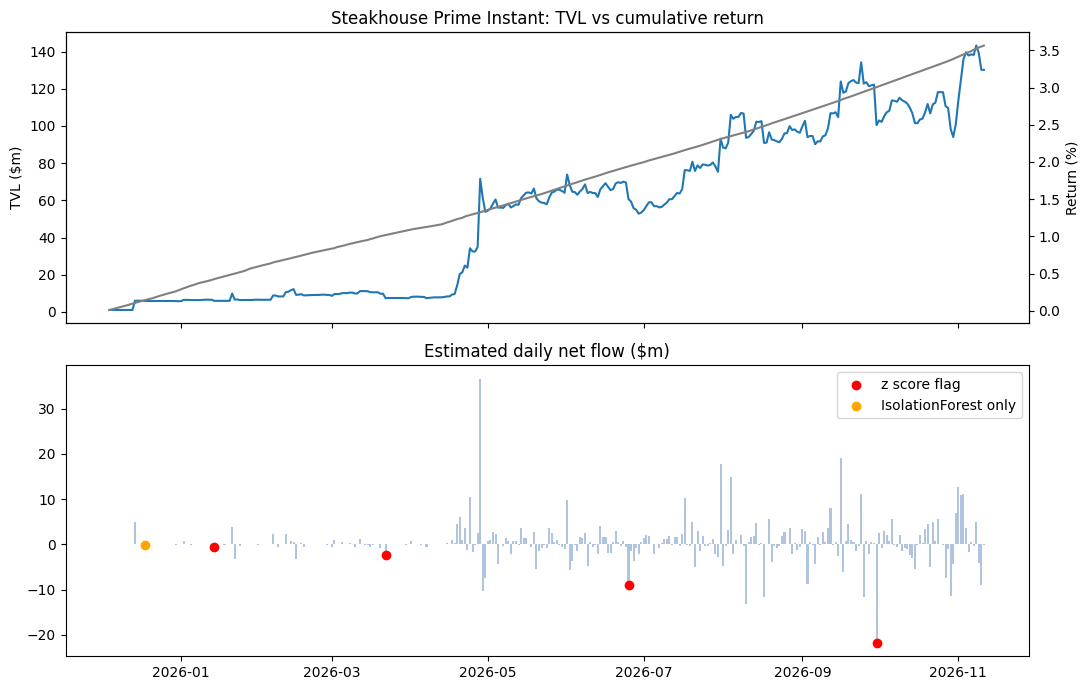

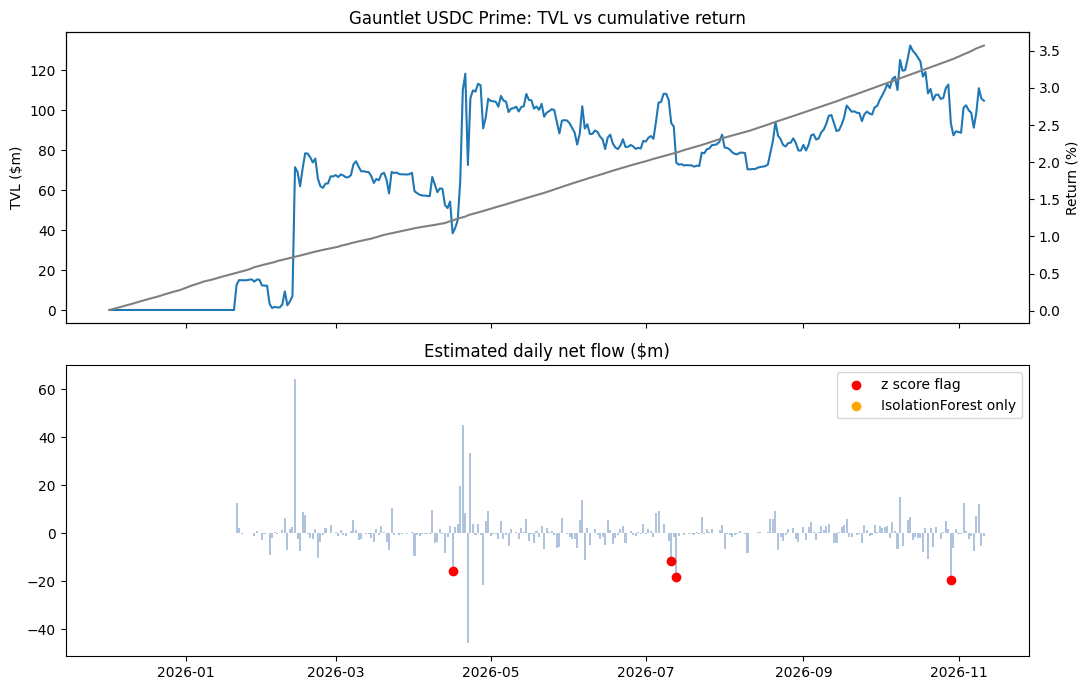

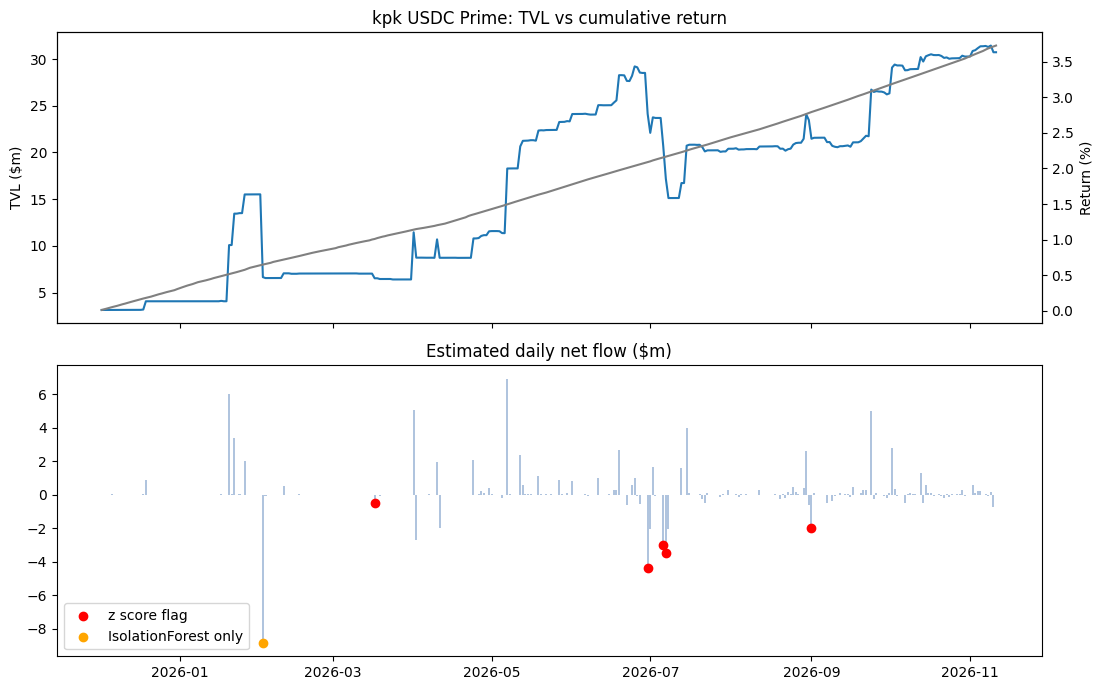

In [60]:
def plot(name, d):
    fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    ax[0].plot(d.index, d["tvlUsd"] / 1e6, label="TVL ($m)")
    ax2 = ax[0].twinx()
    ax2.plot(d.index, d["cum_return"] * 100, color="gray", label="Cumulative return (%)")
    ax[0].set_title(f"{name}: TVL vs cumulative return")
    ax[0].set_ylabel("TVL ($m)"); ax2.set_ylabel("Return (%)")

    ax[1].bar(d.index, d["net_flow"] / 1e6, color="lightsteelblue")
    f = d[d["flag_z"]]; g = d[d["flag_if"] & ~d["flag_z"]]
    ax[1].scatter(f.index, f["net_flow"] / 1e6, color="red", label="z score flag", zorder=3)
    ax[1].scatter(g.index, g["net_flow"] / 1e6, color="orange", label="IsolationForest only", zorder=3)
    ax[1].set_title("Estimated daily net flow ($m)"); ax[1].legend()
    plt.tight_layout(); plt.show()

for name, d in out.items():
    plot(name, d)

In [61]:
for name, d in out.items():
    print(name)
    display(d[d["flag_z"] | d["flag_if"]][["tvlUsd", "net_flow", "z", "flag_z", "flag_if"]])

Steakhouse Prime Instant


,tvlUsd,net_flow,z,flag_z,flag_if
date,,,,,
2025-12-18,5845043,-1.514664e+05,NaN,False,True
2026-01-14,5925414,-5.998611e+05,-4.124493,True,False
2026-03-22,7403141,-2.367171e+06,-6.190602,True,False
2026-06-25,60667471,-8.880283e+06,-3.121171,True,False
2026-09-30,100484588,-2.178833e+07,-3.725030,True,False


Gauntlet USDC Prime


,tvlUsd,net_flow,z,flag_z,flag_if
date,,,,,
2026-04-16,38452871,-1.588119e+07,-4.337733,True,False
2026-07-11,93500885,-1.160229e+07,-3.073849,True,False
2026-07-13,73684645,-1.814494e+07,-4.573818,True,False
2026-10-29,93394055,-1.940976e+07,-4.127035,True,False


kpk USDC Prime


,tvlUsd,net_flow,z,flag_z,flag_if
date,,,,,
2026-02-02,6652707,-8.866548e+06,-2.318324,False,True
2026-03-17,6528626,-5.002449e+05,-79.444816,True,False
2026-06-30,24140620,-4.385741e+06,-7.008145,True,False
2026-07-06,20674450,-3.027150e+06,-3.024283,True,False
2026-07-07,17180164,-3.496291e+06,-3.415358,True,False
2026-09-01,21471559,-2.006781e+06,-3.817910,True,False


In [62]:
pools[pools.project.isin(["yearn-finance", "euler-v2"]) & (pools.chain == "Ethereum") & pools.symbol.str.contains("USDC")][["pool", "project", "symbol", "tvlUsd", "apyBase"]]

,pool,project,symbol,tvlUsd,apyBase
4152,2b181181-f200-44d0-81bf-31f3575fea4c,euler-v2,USDC,339891,2.81138
4385,fa68041a-2ce5-4ee5-88a0-ec5185f0bdb7,euler-v2,USDC,303269,0.47303
4436,ea1a5fae-2b37-57fa-9477-152a684766c5,euler-v2,USDC,295643,5.15519
4700,a0f53224-c152-416e-8599-4563e70c6040,euler-v2,USDC,262496,4.92447
7483,5ee539c7-cfae-41c7-8bf4-b3d2522c33f0,euler-v2,USDC,91137,3.65313
8368,31a0cd94-b781-4e0d-a9f1-1702bc2c238f,euler-v2,USDC,71950,3.22486
10614,e945826d-6546-4f29-b276-9583ce2f0f68,euler-v2,USDC,38738,4.62779
10989,0fde8996-ecdf-441c-94a9-ec67403e9b8c,euler-v2,USDC,33921,2.68235
12456,2f8f9dcc-c471-4205-9ca2-8f803a7eef09,yearn-finance,CRVUSDCWETHINV,21526,0.32000
12921,939b0cda-7d65-41b8-9226-f28949a857e8,euler-v2,USDC,18694,0.00003


In [63]:
d["flag_z"] = (d["z"] <= -3) & (d["net_flow"] < -250_000)

## Limits

1. TVL comes from DeFiLlama, not onchain data, and is measured in USD. I used only USDC vaults so that price moves don't show up as flows.
2. apyBase is a smoothed annual figure, not the return earned each day, so return volatility looks lower than it really is.
3. The data is daily. A deposit and a withdrawal on the same day cancel out, and the snapshot time varies. That's why Gauntlet's 29 Oct estimate (19.41m) is higher than the onchain figure for that calendar day (16.62m).
4. Missing days are left blank, not filled in.
5. The z score gives false flags when recent flows are close to zero. Gauntlet on 18 Jan ($1,025) and kpk on 17 Mar (z of minus 79) are examples. A minimum outflow filter of $250k removes them.
6. There are no labelled anomalies, so I can't score precision formally. Instead I checked the four largest flags against Deposit and Withdraw events: three matched within 1%, and the fourth gap came from snapshot timing. The 3 sigma threshold and 1% contamination are still assumptions.

## Next step

Automate the event check with web3.py and use convertToAssets() for the real share price, so every day is checked against onchain data, not just the flagged ones.

In [64]:
   d["flag_z"] = (d["z"] <= -3) & (d["net_flow"] < -250_000)